# L'OBJECTIF EST D'AGREGER LES DONNEES DES APL 

## 1-Importation, visualisation et nettoyage

In [28]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openpyxl

Pour favoriser la reproductibilité, nous feront en sorte que les données puissent être téléchargées en ligne

In [29]:
def telecharger(url, chemin):
    """Télécharge url et l'enregistre dans chemin (sans retélécharger si le fichier existe)."""
    if os.path.exists(chemin):
        return
    os.makedirs(os.path.dirname(chemin), exist_ok=True)
    reponse = requests.get(url, timeout=60)
    reponse.raise_for_status()                 # erreur claire si le lien est mort
    with open(chemin, "wb") as f:
        f.write(reponse.content)

URL_APL = "https://data.drees.solidarites-sante.gouv.fr/api/datasets/1.0/530_l-accessibilite-potentielle-localisee-apl/attachments/indicateur_d_apl_aux_medecins_generalistes_xlsx/"
telecharger(URL_APL, "data/raw/apl.xlsx")

# Contrôle : on doit voir les feuilles Paramètres, APL 2022, APL 2023, APL 2024
print(pd.ExcelFile("data/raw/apl.xlsx").sheet_names)

/tmp/ipykernel_94583/2581135136.py:15: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  print(pd.ExcelFile("data/raw/apl.xlsx").sheet_names)


['Paramètres', 'APL 2022', 'APL 2023', 'APL 2024']


In [30]:
# Lecture de la feuille APL 2024 : on saute les 8 lignes de titre, la ligne 9 devient l'en-tête
apl = pd.read_excel("data/raw/apl.xlsx", sheet_name="APL 2024", skiprows=8, dtype=str)

# La première ligne lue est la ligne d'unités : on la supprime
apl = apl.iloc[1:]


#visualisation de la base 
apl.head(3)                 

/tmp/ipykernel_94583/1492227594.py:2: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  apl = pd.read_excel("data/raw/apl.xlsx", sheet_name="APL 2024", skiprows=8, dtype=str)


,Code commune INSEE,Commune,APL aux médecins généralistes,APL aux médecins généralistes de 65 ans ou moins,APL aux médecins généralistes de 62 ans ou moins,APL aux médecins généralistes de 60 ans ou moins,Population standardisée 2022 pour la médecine générale,Population totale 2022
1,01001,L'Abergement-Clémenciat,1.953,1.789,1.513,1.259,864.967,859
2,01002,L'Abergement-de-Varey,2.211,1.767,1.345,1.345,264.671,273
3,01004,Ambérieu-en-Bugey,3.098,2.52,2.029,1.907,15282.591,15553.99999999999


Nous allons à présent procéder au renommage des colonnes de la base

In [31]:
#renommage des colonnes 
#  Noms courts 
apl.columns = ["codgeo", "commune", "apl", "apl65", "apl62", "apl60",
               "pop_std", "pop_tot"]

In [32]:
print(apl.dtypes)

codgeo     str
commune    str
apl        str
apl65      str
apl62      str
apl60      str
pop_std    str
pop_tot    str
dtype: object


In [33]:
#transformation en numérique
apl[["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot"]] = apl[["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot"]].apply(pd.to_numeric)

In [34]:
#valeurs manquantes
apl.isna().sum()

codgeo     0
commune    0
apl        0
apl65      0
apl62      0
apl60      0
pop_std    0
pop_tot    0
dtype: int64

A l'issue des traitements préliminaires, on se rend compte que la base ne contient pas de valeurs manquantes

## 2-Début de fusion entre la base des apl et celle contenant la repartition géographique de l'INSEE

In [35]:
#importation de la base contenant les communes, régions et départements

fichier = "data/raw/table-appartenance-geo-communes-2025.xlsx"
cols = ["CODGEO", "LIBGEO", "DEP", "REG", "ARR"]

com = pd.read_excel(fichier, sheet_name="COM", header=5, dtype=str, usecols=cols, engine="calamine") 
geo = com

In [36]:
len(geo)

34875

In [37]:
len(apl)

34890

Avant de procéder à la fusion, nous regardons si les deux bases ont le même nombre d'observations

In [38]:
def codes_absents(apl, geo):
    codes_geo = set(geo["CODGEO"])
    absents = []
    for code in apl["codgeo"]:
        if code not in codes_geo:
            absents.append(code)

    print("Nombre de codes absents :", len(absents))

    for code in absents:
        ligne = apl[apl["codgeo"] == code]
        print(code, ligne["commune"].values[0], round(ligne["pop_tot"].values[0]))

    return absents

In [39]:
codes_absents(apl, geo)

Nombre de codes absents : 45
13201 Marseille 1er Arrondissement 38482
13202 Marseille 2e Arrondissement 24153
13203 Marseille 3e Arrondissement 55653
13204 Marseille 4e Arrondissement 49744
13205 Marseille 5e Arrondissement 45020
13206 Marseille 6e Arrondissement 38804
13207 Marseille 7e Arrondissement 34866
13208 Marseille 8e Arrondissement 83414
13209 Marseille 9e Arrondissement 76347
13210 Marseille 10e Arrondissement 59852
13211 Marseille 11e Arrondissement 59033
13212 Marseille 12e Arrondissement 64276
13213 Marseille 13e Arrondissement 93425
13214 Marseille 14e Arrondissement 59230
13215 Marseille 15e Arrondissement 79501
13216 Marseille 16e Arrondissement 15415
69381 Lyon 1er Arrondissement 29040
69382 Lyon 2e Arrondissement 29880
69383 Lyon 3e Arrondissement 101523
69384 Lyon 4e Arrondissement 35232
69385 Lyon 5e Arrondissement 48277
69386 Lyon 6e Arrondissement 50718
69387 Lyon 7e Arrondissement 87491
69388 Lyon 8e Arrondissement 84956
69389 Lyon 9e Arrondissement 53657
75101 

['13201',
 '13202',
 '13203',
 '13204',
 '13205',
 '13206',
 '13207',
 '13208',
 '13209',
 '13210',
 '13211',
 '13212',
 '13213',
 '13214',
 '13215',
 '13216',
 '69381',
 '69382',
 '69383',
 '69384',
 '69385',
 '69386',
 '69387',
 '69388',
 '69389',
 '75101',
 '75102',
 '75103',
 '75104',
 '75105',
 '75106',
 '75107',
 '75108',
 '75109',
 '75110',
 '75111',
 '75112',
 '75113',
 '75114',
 '75115',
 '75116',
 '75117',
 '75118',
 '75119',
 '75120']

Donc 45 codes de la base APL (arrondissements municipaux de Paris, Lyon et Marseille) ne figurent pas dans la table d’appartenance des communes. 

# 3-Rattachement des codes restants 

Nous possédons la répartition géographique avec les codes régions, les arrondissements, départements et communes correspondants donc nous allons les utiliser. Ces derniers proviennent de l'INSEE 

In [40]:
#les répartitions se sont faits dans deux différents fichiers donc il a fallu faire une concaténation pour obtenir une base de 
#commune complète

fichier = "data/raw/table-appartenance-geo-communes-2025.xlsx"
cols = ["CODGEO", "LIBGEO", "DEP", "REG", "ARR"]

com = pd.read_excel(fichier, sheet_name="COM", header=5, dtype=str, usecols=cols, engine="calamine") 
arm = pd.read_excel(fichier, sheet_name="ARM", header=5, dtype=str, usecols=cols, engine="calamine")

df = pd.concat([com, arm], ignore_index=True) #permet de jetter les anciens indices et d'en créer un autre 

In [41]:
geo2 = df
codes_absents(apl, geo2)

Nombre de codes absents : 0


[]

Nous avons maintenant 0 absents donc nous pouvons faire la fusion et obtenir la base finale

In [42]:
df = pd.merge(left=apl, right=geo2[["CODGEO", "DEP", "REG", "ARR"]],
              left_on="codgeo", right_on="CODGEO", how="left")
df.head()
df.dtypes

codgeo         str
commune        str
apl        float64
apl65      float64
apl62      float64
apl60      float64
pop_std    float64
pop_tot    float64
CODGEO         str
DEP            str
REG            str
ARR            str
dtype: object

In [43]:
print(len(apl), len(df))        
print(df["REG"].isna().sum())  

34890 34890
0


# 4-Agrégation

In [44]:
def agreger(df, niveau, indicateur="apl"):
    """Cette fonction calcule l'APL moyen pondéré par la population standardisée, par territoire."""
    d = df.copy()
    d["pond"] = d[indicateur] * d["pop_std"]            # APL × population standardisée
    res = d.groupby(niveau)[["pond", "pop_std", "pop_tot"]].sum()
    res[indicateur] = res["pond"] / res["pop_std"]      # somme pondérée / somme des poids
    return res[[indicateur, "pop_std", "pop_tot"]].reset_index()

In [45]:
apl_reg = agreger(df, "REG")
apl_dep = agreger(df, "DEP")
apl_arr = agreger(df, ["DEP", "ARR"])   # DEP + ARR pour que chaque arrondissement soit unique


# 5-Visualisation de la base et analyse des disparités

## A- Dispersion de l'APL à différentes echelles

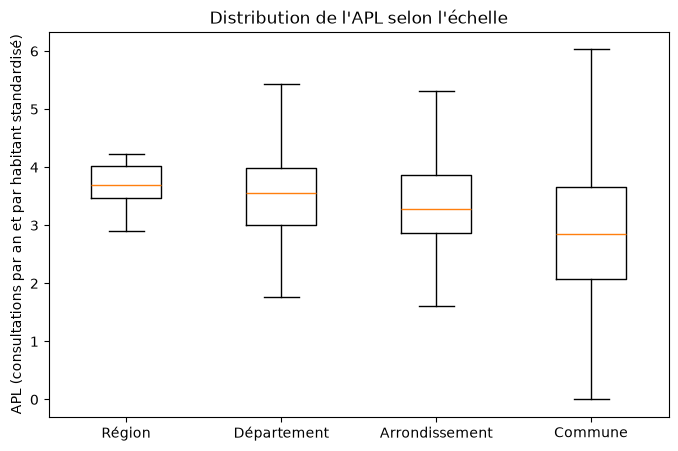

In [46]:
# Les 4 séries d'APL à comparer
donnees = [apl_reg["apl"], apl_dep["apl"], apl_arr["apl"], df["apl"]]
noms = ["Région", "Département", "Arrondissement", "Commune"]

plt.figure(figsize=(8, 5))
plt.boxplot(donnees, showfliers=False)                # showfliers=False : on masque les valeurs extrêmes
plt.xticks([1, 2, 3, 4], noms)                        # noms des échelles sous chaque boîte
plt.ylabel("APL (consultations par an et par habitant standardisé)")
plt.title("Distribution de l'APL selon l'échelle")
plt.show()

Ce graphique laisse apparaitre des inégalités locales. On se rend compte que la dispersion aux échelles plus grande est moins prononcée que lorsqu'on analyse en profondeur. Donc le phénomène d'accès aux medecins devrait être étudié à différentes échelles pour percevoir les disparités

In [47]:
seuil = 2.5 #seuil de la DREES

sous = df[df["apl"] <= seuil].groupby("DEP")["pop_tot"].sum()   # habitants dans une commune sous le seuil
tot = df.groupby("DEP")["pop_tot"].sum()                        # habitants du département
part_dep = (sous / tot).fillna(0).sort_values(ascending=False)

print(part_dep.head(10).round(3))   # les 10 départements les plus touchés

DEP
95     0.691
973    0.684
91     0.644
77     0.609
28     0.593
18     0.578
78     0.539
01     0.522
89     0.508
48     0.490
Name: pop_tot, dtype: float64


Dans le département 95, 69.1% des habitants vivent dans une commune où l’APL est inférieur ou égal à 2,5 consultations par an et par habitant. Ces habitants ont donc, en moyenne, un accès faible aux médecins généralistes selon le critère de la DREES. L'interpretation reste la même pour les autres départements.

## B- APL moyen par région

   REG                         nom   apl     pop_tot
2   03                      Guyane  1.76    288382.0
5   24         Centre-Val de Loire  2.91   2581597.0
4   11               Île-de-France  3.35  12380964.0
6   27     Bourgogne-Franche-Comté  3.43   2803977.0
10  52            Pays de la Loire  3.47   3879216.0
7   28                   Normandie  3.49   3339074.0
14  84        Auvergne-Rhône-Alpes  3.56   8163884.0
0   01                  Guadeloupe  3.57    383569.0
1   02                  Martinique  3.70    361019.0
13  76                   Occitanie  3.84   6080731.0
16  94                       Corse  3.90    351276.0
9   44                   Grand Est  3.95   5560079.0
12  75          Nouvelle-Aquitaine  4.02   6113384.0
11  53                    Bretagne  4.02   3422845.0
8   32             Hauts-de-France  4.05   5998916.0
15  93  Provence-Alpes-Côte d'Azur  4.23   5170312.0
3   04                  La Réunion  5.44    881348.0


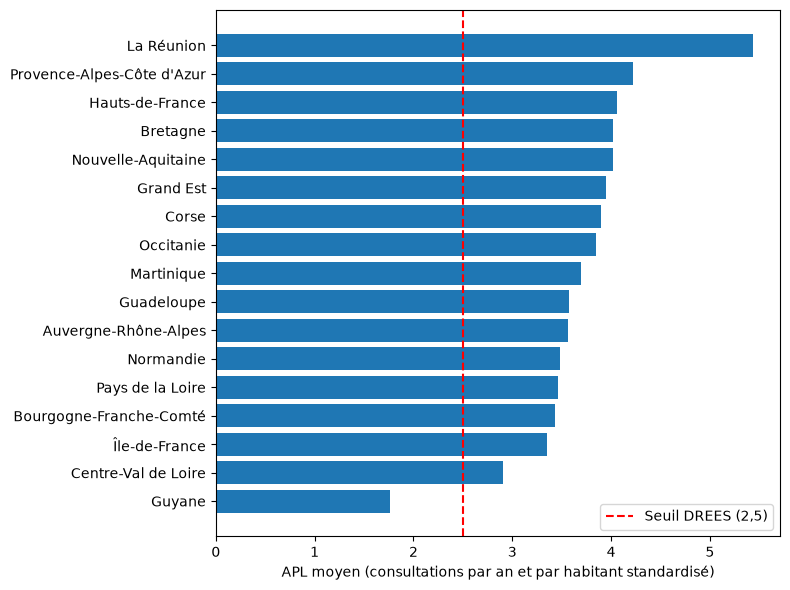

In [48]:
noms_reg = {"01": "Guadeloupe", "02": "Martinique", "03": "Guyane", "04": "La Réunion",
            "11": "Île-de-France", "24": "Centre-Val de Loire", "27": "Bourgogne-Franche-Comté",
            "28": "Normandie", "32": "Hauts-de-France", "44": "Grand Est", "52": "Pays de la Loire",
            "53": "Bretagne", "75": "Nouvelle-Aquitaine", "76": "Occitanie",
            "84": "Auvergne-Rhône-Alpes", "93": "Provence-Alpes-Côte d'Azur", "94": "Corse"}

apl_reg["nom"] = apl_reg["REG"].map(noms_reg)
apl_reg = apl_reg.sort_values("apl")
print(apl_reg[["REG", "nom", "apl", "pop_tot"]].round(2))


import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.barh(apl_reg["nom"], apl_reg["apl"])
plt.axvline(2.5, color="red", linestyle="--", label="Seuil DREES (2,5)")
plt.xlabel("APL moyen (consultations par an et par habitant standardisé)")
plt.legend()
plt.tight_layout()
plt.show()

Les régions sont proches, de 2,91 (Centre-Val de Loire) à près de 6 (La Reunion). Seule la Guyane (1,76) est nettement en dessous du seuil de 2,5, et toutes les autres régions sont au-dessus. Cela confirme que l’échelle régionale cache les inégalités locales, comme on l’a vu avec la part de population sous le seuil par département.

## C- APL par département

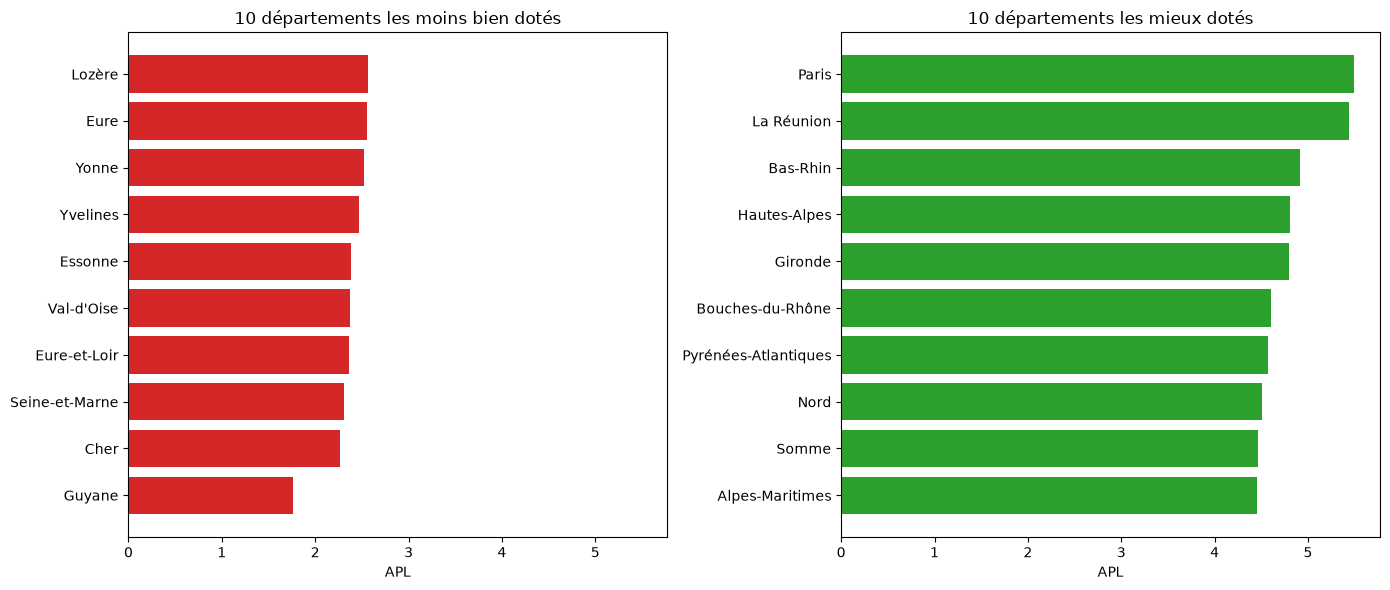

In [49]:
import matplotlib.pyplot as plt

NOMS_DEP = {
    "01": "Ain", "02": "Aisne", "03": "Allier", "04": "Alpes-de-Haute-Provence",
    "05": "Hautes-Alpes", "06": "Alpes-Maritimes", "07": "Ardèche", "08": "Ardennes",
    "09": "Ariège", "10": "Aube", "11": "Aude", "12": "Aveyron",
    "13": "Bouches-du-Rhône", "14": "Calvados", "15": "Cantal", "16": "Charente",
    "17": "Charente-Maritime", "18": "Cher", "19": "Corrèze", "2A": "Corse-du-Sud",
    "2B": "Haute-Corse", "21": "Côte-d'Or", "22": "Côtes-d'Armor", "23": "Creuse",
    "24": "Dordogne", "25": "Doubs", "26": "Drôme", "27": "Eure",
    "28": "Eure-et-Loir", "29": "Finistère", "30": "Gard", "31": "Haute-Garonne",
    "32": "Gers", "33": "Gironde", "34": "Hérault", "35": "Ille-et-Vilaine",
    "36": "Indre", "37": "Indre-et-Loire", "38": "Isère", "39": "Jura",
    "40": "Landes", "41": "Loir-et-Cher", "42": "Loire", "43": "Haute-Loire",
    "44": "Loire-Atlantique", "45": "Loiret", "46": "Lot", "47": "Lot-et-Garonne",
    "48": "Lozère", "49": "Maine-et-Loire", "50": "Manche", "51": "Marne",
    "52": "Haute-Marne", "53": "Mayenne", "54": "Meurthe-et-Moselle", "55": "Meuse",
    "56": "Morbihan", "57": "Moselle", "58": "Nièvre", "59": "Nord",
    "60": "Oise", "61": "Orne", "62": "Pas-de-Calais", "63": "Puy-de-Dôme",
    "64": "Pyrénées-Atlantiques", "65": "Hautes-Pyrénées", "66": "Pyrénées-Orientales",
    "67": "Bas-Rhin", "68": "Haut-Rhin", "69": "Rhône", "70": "Haute-Saône",
    "71": "Saône-et-Loire", "72": "Sarthe", "73": "Savoie", "74": "Haute-Savoie",
    "75": "Paris", "76": "Seine-Maritime", "77": "Seine-et-Marne", "78": "Yvelines",
    "79": "Deux-Sèvres", "80": "Somme", "81": "Tarn", "82": "Tarn-et-Garonne",
    "83": "Var", "84": "Vaucluse", "85": "Vendée", "86": "Vienne",
    "87": "Haute-Vienne", "88": "Vosges", "89": "Yonne", "90": "Territoire de Belfort",
    "91": "Essonne", "92": "Hauts-de-Seine", "93": "Seine-Saint-Denis",
    "94": "Val-de-Marne", "95": "Val-d'Oise",
    "971": "Guadeloupe", "972": "Martinique", "973": "Guyane",
    "974": "La Réunion", "976": "Mayotte",
}

apl_dep = agreger(df, "DEP").reset_index()   # retirez reset_index() si DEP est déjà une colonne
apl_dep["DEP"] = apl_dep["DEP"].astype(str).str.zfill(2)   # "1" -> "01"
apl_dep["nom"] = apl_dep["DEP"].map(NOMS_DEP)

tri = apl_dep.sort_values("apl")
bas, haut = tri.head(10), tri.tail(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

axes[0].barh(bas["nom"], bas["apl"], color="tab:red")
axes[0].set_title("10 départements les moins bien dotés")
axes[0].set_xlabel("APL")

axes[1].barh(haut["nom"], haut["apl"], color="tab:green")
axes[1].set_title("10 départements les mieux dotés")
axes[1].set_xlabel("APL")

plt.tight_layout()
plt.show()

L'analyse de l'APL par département met en évidence de fortes inégalités d'accès aux soins. Paris (environ 5,5) et La Réunion (environ 5,4) sont les territoires les mieux dotés, devant le Bas-Rhin, les Hautes-Alpes et la Gironde (autour de 4,8 à 4,9), tandis que la Guyane se démarque nettement comme le département le moins bien doté (environ 1,8), très loin des autres territoires du bas du classement, qui se situent entre 2,3 et 2,6. Deux profils de départements en difficulté coexistent : des territoires ruraux comme la Lozère, le Cher ou l'Yonne, marqués par une faible densité de professionnels, et des départements de grande couronne parisienne (Seine-et-Marne, Essonne, Val-d'Oise, Yvelines), où la forte population dépasse l'offre disponible malgré la proximité de la capitale. Les départements les mieux dotés correspondent surtout à des territoires abritant de grandes métropoles, qui concentrent l'offre de soins. 

## D- Sauvegarde de la base de données

In [50]:
df.head()
APL_FIN = df.rename(columns={"codgeo": "COM_INSEE"})
APL_FIN.to_excel("data/processed/apl_fin.xlsx", index=False)
APL_FIN.to_csv("data/processed/apl_fin.csv", index=False, encoding="utf-8-sig")

# 6- Statistiques descriptives de la base finale des APL

## A- Calcul des moyennes médianes et autres pour les variables de la base

In [51]:
vars_apl = ["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot"]
d = df

# 1. Statistiques descriptives sur les communes
stats = d[vars_apl].describe(percentiles=[.1, .25, .5, .75, .9]).T
stats["nb_zeros"] = (d[vars_apl] == 0).sum()      # un APL de 0 est une vraie valeur, pas un manquant
display(stats.round(2))

,count,mean,std,min,10%,25%,50%,75%,90%,max,nb_zeros
apl,34890.0,2.92,1.31,0.00,1.39,2.08,2.84,3.66,4.48,23.90,523
apl65,34890.0,2.54,1.23,0.00,1.08,1.73,2.48,3.26,4.07,23.90,690
apl62,34890.0,2.26,1.16,0.00,0.86,1.47,2.18,2.94,3.71,23.90,839
apl60,34890.0,2.09,1.14,0.00,0.74,1.31,1.99,2.75,3.52,15.94,964
pop_std,34890.0,1942.12,8560.94,1.92,105.08,203.44,464.85,1191.93,3338.60,479250.45,0
pop_tot,34890.0,1942.12,8813.45,2.00,101.00,198.00,460.00,1176.00,3253.10,511684.00,0


Le tableau décrit 34 890 unités (communes et 45 arrondissements). L’APL moyen est de 2,92 consultations par an et par habitant, pour une médiane de 2,84 ; un quart des communes est sous 2,08 et 10 % sous 1,39, nettement en dessous du seuil de sous-dotation de 2,5. 523 unités (1,5 %) ont un APL nul. 
En retirant progressivement les médecins les plus âgés, la moyenne tombe à 2,54 (65 ans ou moins) puis 2,09 (60 ans ou moins), et la médiane passe sous le seuil de 2,5 dès les 65 ans ou moins (2,48). Le nombre de communes à APL nul passe de 523 à 964, soit 441 de plus : l’offre actuelle repose donc fortement sur les médecins de plus de 60 ans, ce que le croisement avec la taille des communes permettra de préciser. 
Enfin, la commune médiane compte 460 habitants pour une moyenne de 1 942 : les petites communes dominent en nombre, ce qui justifie les moyennes pondérées par la population utilisées dans la suite.

## B- Part de la population sous le seuil

In [52]:
# 2. Validation nationale : moyenne pondérée et part de population sous le seuil
moy_nat = (d["apl"] * d["pop_std"]).sum() / d["pop_std"].sum()
part_nat = d.loc[d["apl"] <= 2.5, "pop_tot"].sum() / d["pop_tot"].sum()
print(f"APL moyen national (pondéré) : {moy_nat:.2f}")
print(f"Part de la population sous le seuil : {part_nat:.1%}")

APL moyen national (pondéré) : 3.72
Part de la population sous le seuil : 18.2%


Pondéré par la population standardisée, l’APL moyen national est de 3,72 consultations par an et par habitant, contre 2,92 pour la moyenne simple des communes. 18,2 % de la population, soit environ 12 millions d’habitants, vit dans une commune sous-dotée (APL ≤ 2,5).

In [53]:
# 3. Trois classes DREES, avec la part de population dans chacune
# on utilise la borne -0.01 pour inclure les communes avec 0 apl
# float("inf") signifie « pas de borne supérieure »
# observed=True n’affiche que les classes réellement présentes, ce qui évite un avertissement pour les catégories vides.
classe = pd.cut(d["apl"], bins=[-0.01, 2.5, 4, float("inf")], #intervalles fermés à droite par défaut 
                labels=["sous-dotée", "moyennement dotée", "bien dotée"]) 
print((d.groupby(classe, observed=True)["pop_tot"].sum() / d["pop_tot"].sum()).round(3))

apl
sous-dotée           0.182
moyennement dotée    0.429
bien dotée           0.389
Name: pop_tot, dtype: float64


Selon la classification DREES, 18,2 % de la population vit dans une commune sous-dotée (APL ≤ 2,5), 42,9 % dans une commune moyennement dotée (entre 2,5 et 4) et 38,9 % dans une commune bien dotée (APL > 4). La classe intermédiaire est la plus importante : 42,9 % de la population vit dans une commune moyennement dotée (APL entre 2,5 et 4), au-dessus du seuil de sous-dotation sans atteindre le niveau de bonne dotation, donc dans une zone qui pourrait basculer en cas de baisse de l’offre. L’accès est ainsi très inégal : à peine plus d’un habitant sur trois vit dans une commune bien dotée.

## C- Projection en cas de disparition des médecins de plus de 65 ans

In [54]:

parts = d.groupby(classe, observed=True)["pop_tot"].sum() / d["pop_tot"].sum()

part_nat = parts["sous-dotée"]

classe65 = pd.cut(d["apl65"], bins=[-0.01, 2.5, 4, float("inf")],
                  labels=["sous-dotée", "moyennement dotée", "bien dotée"])
parts65 = d.groupby(classe65, observed=True)["pop_tot"].sum() / d["pop_tot"].sum()
print(parts65.round(3))
print("Habitants supplémentaires sous le seuil (millions) :",
      round((parts65["sous-dotée"] - part_nat) * d["pop_tot"].sum() / 1e6, 1))

apl65
sous-dotée           0.290
moyennement dotée    0.444
bien dotée           0.266
Name: pop_tot, dtype: float64
Habitants supplémentaires sous le seuil (millions) : 7.3


**Scénario sans les médecins de plus de 65 ans.** 
Si l'on ne compte que les généralistes de 65 ans ou moins, la part de la population vivant dans une commune sous-dotée passe de 18,2 % à 29 %, soit environ 7.3 millions d'habitants supplémentaires. Ce scénario suppose que ces médecins cessent d'exercer sans être remplacés.

# 7-Conclusion

L'accès aux médecins généralistes est globalement correct en moyenne nationale, mais très inégal selon l'échelle d'observation. L'APL moyen, pondéré par la population, est de 3,72 consultations accessibles par an et par habitant (2,92 en moyenne simple des communes, car les petites communes pèsent autant que les grandes). Environ 18,2 % de la population, soit près de 12 millions de personnes, vit dans une commune sous-dotée (APL ≤ 2,5).

Les inégalités sont masquées par les moyennes régionales : seule la Guyane (1,76) passe sous le seuil au niveau régional, alors que des départements comme le Val-d'Oise comptent près de 70 % de leurs habitants dans des communes sous-dotées. Ces écarts n'apparaissent pleinement qu'à l'échelle communale.

L'offre repose en outre beaucoup sur les médecins âgés : en excluant les médecins de plus de 65 ans, la part de la population sous le seuil passe de 18 % à 29 %, soit environ 7,3 millions de personnes supplémentaires. Le nombre de communes sans aucun accès (APL nul) augmente aussi lorsque l'on retire les plus de 60 ans (523 contre 964).
